### Step 1: Import Required Libraries



In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import random

from torch.utils.data import DataLoader, random_split

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("CUDA Available:", torch.cuda.is_available())


PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
CUDA Available: True


### Step 2: Set Random Seed and Training Parameters


In [17]:
import torch
import numpy as np
import random


SEED = 42
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Random Seed:", SEED)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Device: cuda
Random Seed: 42
Batch Size: 64
Epochs: 10


Step 3: Image Preprocessing and Normalization

In [3]:
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

print("Image preprocessing configured successfully!")

Image preprocessing configured successfully!


Step 4: Load the CIFAR-10 Dataset

In [4]:

import torchvision


train_dataset_full = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)


test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)


class_names = train_dataset_full.classes

print("Training Dataset:", len(train_dataset_full))
print("Test Dataset:", len(test_dataset))
print("Classes:", class_names)


100%|██████████| 170M/170M [32:23<00:00, 87.7kB/s]


Training Dataset: 50000
Test Dataset: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Step 5: Split the Dataset

In [5]:

from torch.utils.data import random_split

train_size = 40000
val_size = 10000

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    train_dataset_full,
    [train_size, val_size],
    generator=generator
)

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))


Training Images: 40000
Validation Images: 10000
Testing Images: 10000


Step 6: Create DataLoaders

In [6]:

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))


Training Batches: 625
Validation Batches: 157
Testing Batches: 157


Step 7: Display Sample CIFAR-10 Images

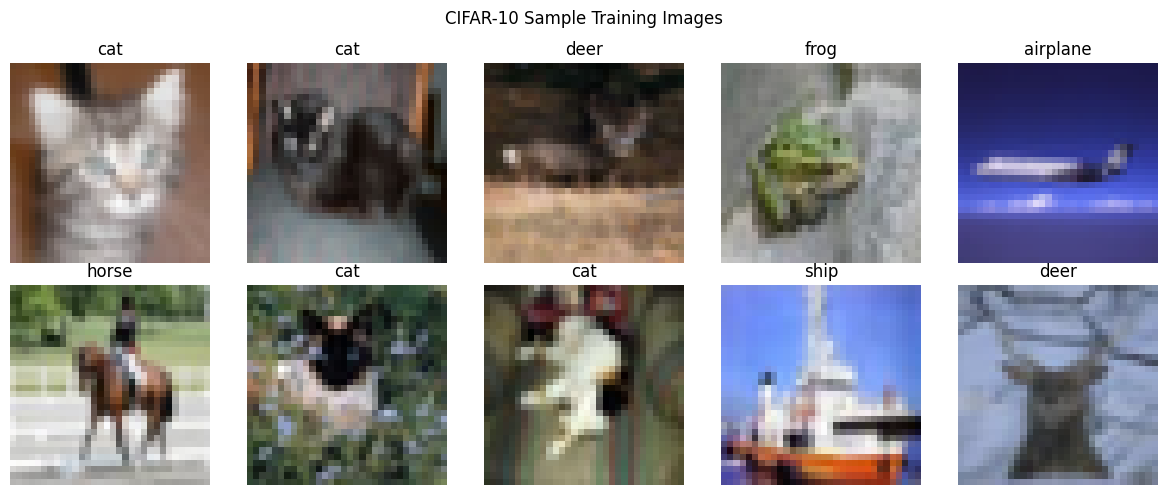

In [7]:

import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(train_loader))

mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.2470, 0.2435, 0.2616])

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    img = images[i].permute(1, 2, 0).numpy()

    img = np.clip(img * std + mean, 0, 1)

    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Training Images")
plt.tight_layout()
plt.show()


Step 8: Create the MLP Model

In [8]:

import torch.nn as nn

class MLPClassifier(nn.Module):

    def __init__(self):
        super(MLPClassifier, self).__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(3072, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.network(x)
        return x


model = MLPClassifier().to(device)

print(model)


MLPClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


Step 9: Calculate Trainable Parameters

In [9]:

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total Trainable Parameters:", total_params)




Total Trainable Parameters: 1707274


Step 10: Set Loss Function and Optimizer

In [10]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer: Adam")
print("Learning Rate:", 0.001)
print("Device:", device)

Loss Function: CrossEntropyLoss()
Optimizer: Adam
Learning Rate: 0.001
Device: cuda


Step 11: Train and Validate the MLP Model

In [11]:

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

print("\nTraining Completed Successfully!")


Epoch [1/10] | Train Loss: 1.6791 | Train Acc: 40.37% | Val Loss: 1.5682 | Val Acc: 44.80%
Epoch [2/10] | Train Loss: 1.4895 | Train Acc: 47.31% | Val Loss: 1.5164 | Val Acc: 46.20%
Epoch [3/10] | Train Loss: 1.3836 | Train Acc: 50.98% | Val Loss: 1.5021 | Val Acc: 48.17%
Epoch [4/10] | Train Loss: 1.3017 | Train Acc: 53.89% | Val Loss: 1.4403 | Val Acc: 49.89%
Epoch [5/10] | Train Loss: 1.2220 | Train Acc: 56.66% | Val Loss: 1.4398 | Val Acc: 51.00%
Epoch [6/10] | Train Loss: 1.1519 | Train Acc: 59.13% | Val Loss: 1.4119 | Val Acc: 51.54%
Epoch [7/10] | Train Loss: 1.0793 | Train Acc: 61.33% | Val Loss: 1.4720 | Val Acc: 51.01%
Epoch [8/10] | Train Loss: 1.0180 | Train Acc: 63.66% | Val Loss: 1.4841 | Val Acc: 51.73%
Epoch [9/10] | Train Loss: 0.9600 | Train Acc: 65.51% | Val Loss: 1.5459 | Val Acc: 51.23%
Epoch [10/10] | Train Loss: 0.8981 | Train Acc: 67.84% | Val Loss: 1.5867 | Val Acc: 51.04%

Training Completed Successfully!


Step 12: Plot Training and Validation Loss

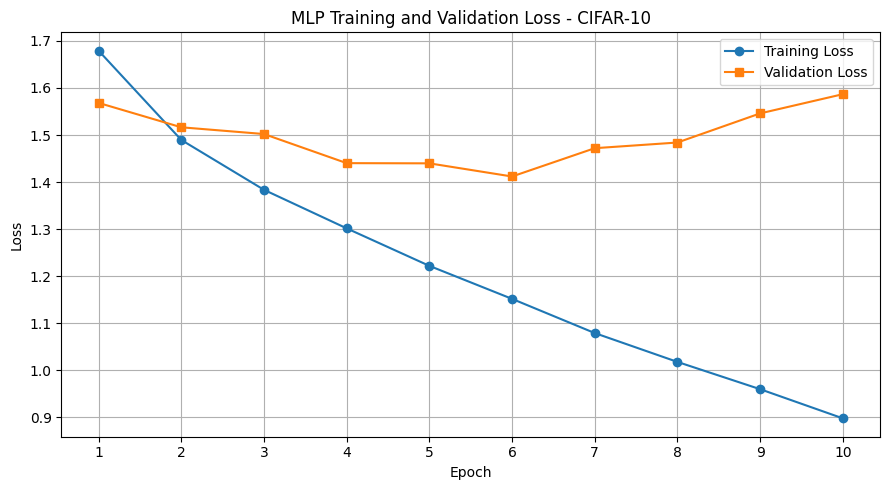

Loss graph saved successfully!


In [12]:

import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training and Validation Loss - CIFAR-10")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig("MLP_Loss_Graph.png", dpi=300)

plt.show()

print("Loss graph saved successfully!")


Step 13: Plot Training and Validation Accuracy

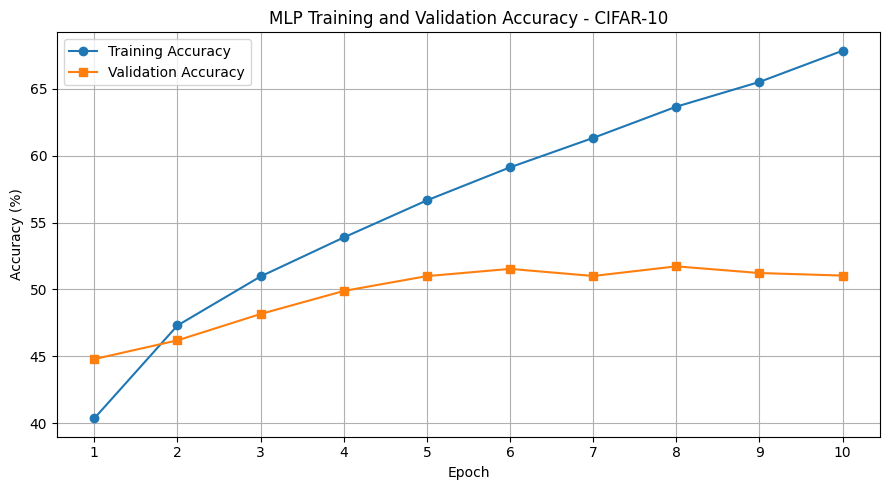

Accuracy graph saved successfully!


In [13]:

import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_accuracies,
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MLP Training and Validation Accuracy - CIFAR-10")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig("MLP_Accuracy_Graph.png", dpi=300)

plt.show()

print("Accuracy graph saved successfully!")


Step 14: Evaluate the MLP Model on Test Data

In [14]:

model.eval()

test_loss_sum = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss_sum += loss.item() * labels.size(0)

        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_loss = test_loss_sum / test_total
test_accuracy = 100 * test_correct / test_total

print("===== MLP FINAL TEST RESULTS =====")
print(f"Test Images: {test_total}")
print(f"Correct Predictions: {test_correct}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")


===== MLP FINAL TEST RESULTS =====
Test Images: 10000
Correct Predictions: 5081
Test Loss: 1.5716
Test Accuracy: 50.81%


Step 15: Save the Final MLP Results

In [15]:

import pandas as pd

results = pd.DataFrame({
    "Model": ["MLP"],
    "Train Accuracy (%)": [round(train_accuracies[-1], 2)],
    "Validation Accuracy (%)": [round(val_accuracies[-1], 2)],
    "Test Accuracy (%)": [round(test_accuracy, 2)],
    "Train Loss": [round(train_losses[-1], 4)],
    "Validation Loss": [round(val_losses[-1], 4)],
    "Test Loss": [round(test_loss, 4)],
    "Trainable Parameters": [total_params]
})

display(results)

results.to_csv("Exercise1_MLP_Results.csv", index=False)

print("MLP results saved successfully!")


,Model,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train Loss,Validation Loss,Test Loss,Trainable Parameters
0,MLP,67.84,51.04,50.81,0.8981,1.5867,1.5716,1707274


MLP results saved successfully!


Step 16: Save the Trained MLP Model

In [16]:

# Save trained MLP model
torch.save(
    model.state_dict(),
    "Exercise1_MLP_Model.pth"
)

print("MLP model saved successfully!")


MLP model saved successfully!
